# DRL trading agent – walkthrough

One full run of the pipeline on a **synthetic** market (regime-switching, with a deliberately planted sentiment edge):

1. Generate and clean data
2. Model transaction costs (spread + slippage)
3. Build features and split chronologically: train / dev / test / holdout
4. Train a PPO actor-critic agent (GRU encoders per data type), first on PnL, then on the Sharpe ratio
5. Backtest out of sample and run the go-live checklist

> Synthetic data validates the *pipeline*, not a strategy. Numbers here say nothing about real markets.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from drl_fx import data as D
from drl_fx.synthetic import make_market
from drl_fx.env import TradingEnv
from drl_fx.agent import build_agent, train_two_stage
from drl_fx.evaluate import backtest, buy_and_hold, metrics, by_regime, go_live_checklist
PPY = 6552   # bars per year used to annualise Sharpe ratios in this synthetic demo

## 1. Data and cleaning

In [2]:
raw = make_market(n=60_000, seed=0).set_index('timestamp')
print(D.check_data_size(raw)['note'])
df, report = D.clean(raw)          # forward-fill short gaps (no look-ahead), drop bad periods
report

Only 60,000 rows; course guideline is >= 100,000. Treat backtest results with caution.


{'rows_in': 60000,
 'nan_cells_in': 348,
 'periods_dropped': 0,
 'rows_out': 60000}

## 2. Transaction costs
Half the bid-ask spread plus square-root market impact `k·σ·√(trade size / volume)`.

In [3]:
cost = D.estimate_costs(df, trade_notional=100_000)
(cost * 1e4).describe().round(2).to_frame('one-way cost, bp')

,"one-way cost, bp"
count,60000.00
mean,0.90
std,0.33
min,0.46
25%,0.66
50%,0.78
75%,1.06
max,3.00


## 3. Features and chronological splits
Normalisation is fitted on the training split only.

In [4]:
f, price_cols, sent_cols = D.make_features(df, cost)
cols = price_cols + sent_cols
sp = D.chronological_splits(f)
sp['train'], sp['dev'], sp['test'], sp['holdout'] = D.normalize(sp['train'], [sp['dev'], sp['test'], sp['holdout']], cols)
regimes = D.label_regimes(f)
pd.DataFrame({k: [v.index.min(), v.index.max(), len(v)] for k, v in sp.items()}, index=['start', 'end', 'bars']).T

,start,end,bars
train,2018-01-01 05:00:00,2019-01-11 01:30:00,35987
dev,2019-01-11 01:45:00,2019-04-14 18:30:00,8996
test,2019-04-14 18:45:00,2019-07-17 11:30:00,8996
holdout,2019-07-17 11:45:00,2019-09-17 23:30:00,6000


## 4. Train the agent
One GRU encoder for price/volume, one for sentiment → PPO policy choosing **buy / sell / hold**. Stage 1 rewards net PnL; stage 2 the differential Sharpe ratio with a lower learning rate.

In [5]:
W = 20
groups = [list(range(len(price_cols))), list(range(len(price_cols), len(cols)))]
make_env = lambda reward: (lambda seed: TradingEnv(sp['train'], cols, window=W, reward=reward, seed=seed))
model = build_agent(make_env('pnl'), W, groups, seed=0)
model = train_two_stage(model, make_env('sharpe'), steps_pnl=40_000, steps_sharpe=20_000)

## 5. Out-of-sample backtest

In [6]:
hist = {k: backtest(model, sp[k], cols, W) for k in sp}
M = {k: metrics(h, PPY) for k, h in hist.items()}
M['holdout_bh'] = metrics(buy_and_hold(sp['holdout'], W), PPY)
M['holdout_2x_cost'] = metrics(backtest(model, sp['holdout'], cols, W, cost_mult=2.0), PPY)
pd.DataFrame(M).T[['sharpe', 'max_drawdown_%', 'turnover_per_bar', 'cost_drag_%']]

,sharpe,max_drawdown_%,turnover_per_bar,cost_drag_%
train,3.63,-8.45,0.020,5.61
dev,4.91,-16.22,0.017,1.53
test,3.74,-9.49,0.019,1.45
holdout,2.67,-10.81,0.022,1.00
holdout_bh,2.81,-7.40,0.000,0.00
holdout_2x_cost,2.60,-10.88,0.022,2.01


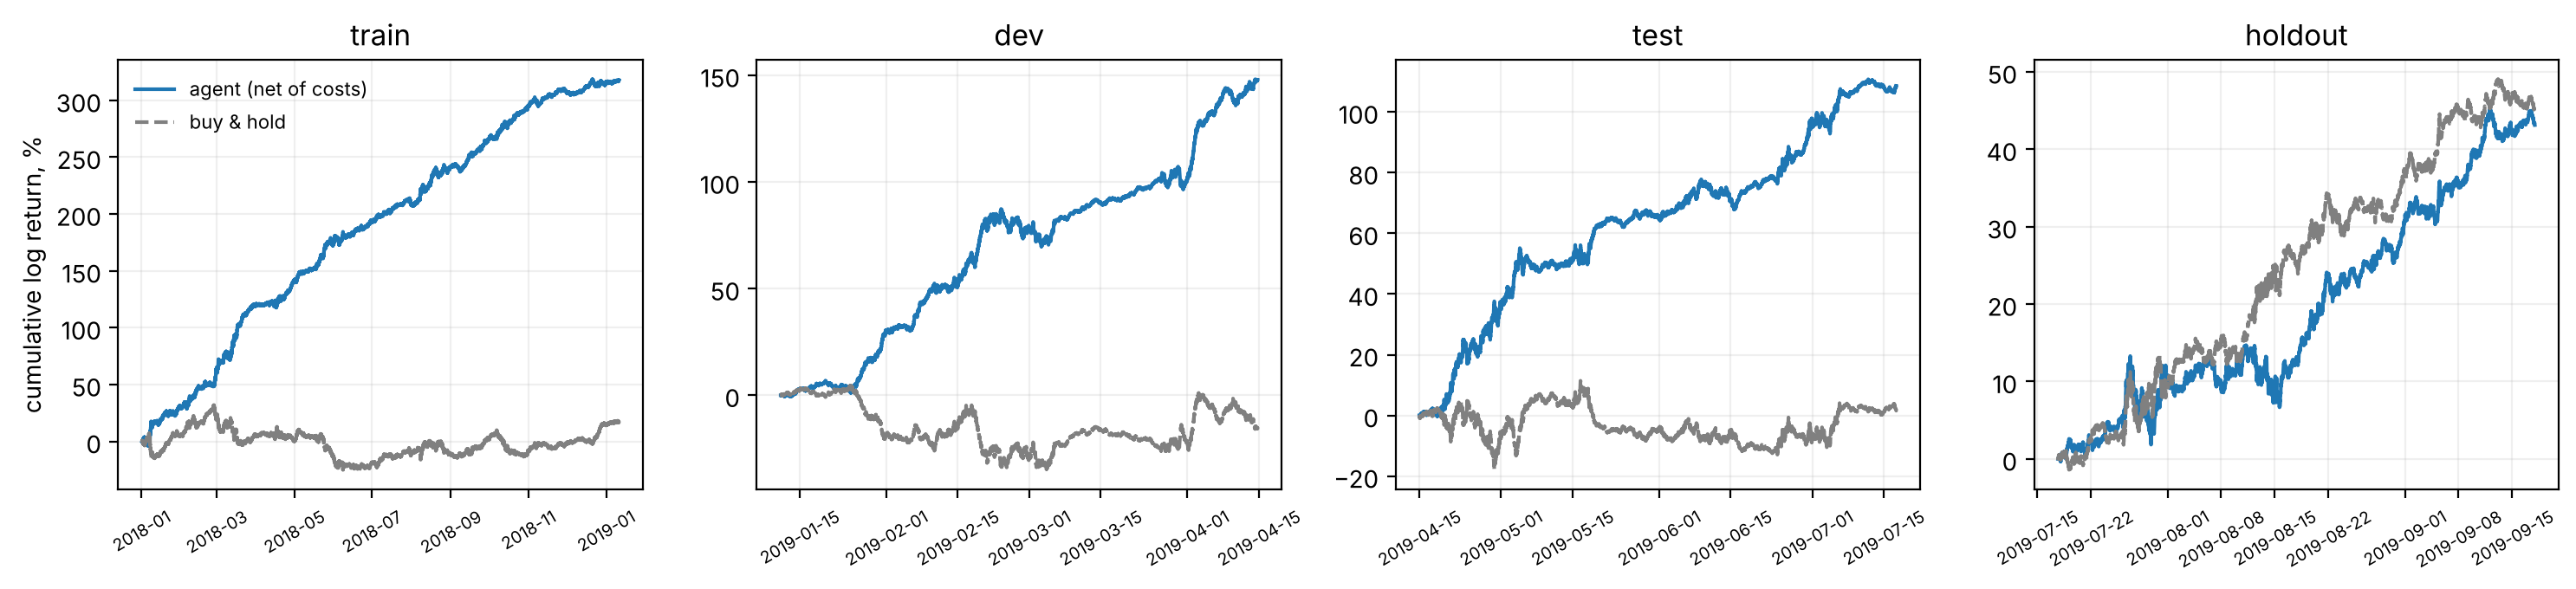

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, k in zip(axes, ['train', 'dev', 'test', 'holdout']):
    ax.plot(hist[k]['net'].cumsum() * 100, label='agent (net of costs)')
    ax.plot(buy_and_hold(sp[k], W)['net'].cumsum() * 100, ls='--', color='grey', label='buy & hold')
    ax.set_title(k); ax.tick_params(axis='x', labelrotation=30, labelsize=7); ax.grid(alpha=.2)
axes[0].set_ylabel('cumulative log return, %'); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Performance by market regime (test + holdout)

In [8]:
reg = by_regime(pd.concat([hist['test'], hist['holdout']]), regimes, PPY)
reg[['sharpe', 'max_drawdown_%', 'bars']]

,sharpe,max_drawdown_%,bars
down,2.22,-6.14,3217.0
steady,3.55,-4.61,3291.0
up,3.12,-6.19,3734.0
volatile,4.25,-10.81,4712.0


## 6. Go-live checklist
The transfer test (an untrained security) is skipped here; run `python -m drl_fx.run --csv ... --transfer-csv ...` for the full check.

In [9]:
res = {'data_size': D.check_data_size(raw), 'metrics': M, 'regimes_test_holdout': reg}
pd.set_option('display.max_colwidth', 120)
go_live_checklist(res, PPY)

,check,pass,detail
0,Data size >= 100k rows,False,"Only 60,000 rows; course guideline is >= 100,000. Treat backtest results with caution."
1,Train / dev / test consistent,True,"OK: decent in train, dev and test. Proceed to holdout, then fine-tune with a small LR and paper trade."
2,Holdout (never seen) Sharpe >= threshold,True,holdout Sharpe 2.67 vs threshold 0.5
3,Beats buy-and-hold on holdout (risk-adjusted),False,"agent 2.67 vs B&H 2.81, excess Sharpe vs B&H -0.1"
4,"Not stuck in one position (always long, short or flat)",True,"correlation with B&H 0.016, turnover/bar 0.022"
5,Out-of-sample data covers up/down/steady/volatile,True,"regimes present: ['down', 'steady', 'up', 'volatile']"
6,No regime with badly negative Sharpe,True,weak regimes: none
7,Survives 2x transaction costs,True,holdout Sharpe at 2x costs: 2.6
8,"Works on an untrained security, same timestep",False,not run: pass --transfer-csv


**Reading the result:** the agent is profitable after costs in every split and regime, and survives doubled costs, but it is **not ready**. This short demo uses fewer than 100k rows, the agent does not beat buy-and-hold on a risk-adjusted basis in the holdout period, and the transfer test has not been run. The checklist exists to stop a model that only looks good in backtests.

## Next steps
- Replace the synthetic data with real intraday data and a real sentiment series (e.g. Fed press-conference sentiment), aligned so each bar only sees information published before it.
- Walk-forward retraining and ensemble re-weighting.
- Paper trade before risking any capital.